# Exercice 2 — Classifier les chiffres MNIST (réseau entièrement connecté)

Objectif : utiliser des **mini-lots** (`DataLoader`) et évaluer un modèle sur des données de test.

> Le premier lancement télécharge MNIST (~50 Mo) dans `data/`.

## Chargement des données et modèle

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Images d'entraînement :", len(train_dataset), "| images de test :", len(test_dataset))
print(model)
print("Paramètres :", sum(p.numel() for p in model.parameters()))

Images d'entraînement : 60000 | images de test : 10000
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Paramètres : 101770


## 1. Entraînement pendant 5 époques (mode `train()`)

In [2]:
epochs = 5
historique = []

for epoch in range(epochs):
    model.train()
    total_loss, total = 0.0, 0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)              # logits (B, 10), sans Softmax
        loss = criterion(outputs, labels)    # étiquettes entières (B,)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total += images.size(0)

    historique.append(total_loss / total)
    print(f"Époque {epoch + 1}/{epochs} | Perte moyenne : {historique[-1]:.4f}")

Époque 1/5 | Perte moyenne : 0.3448


Époque 2/5 | Perte moyenne : 0.1580


Époque 3/5 | Perte moyenne : 0.1083


Époque 4/5 | Perte moyenne : 0.0812


Époque 5/5 | Perte moyenne : 0.0640


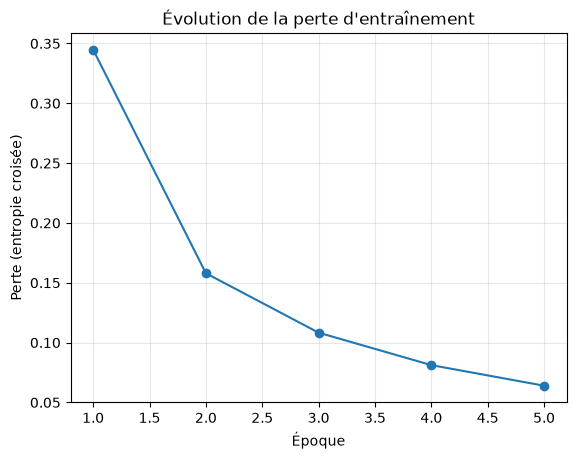

In [3]:
plt.plot(range(1, epochs + 1), historique, marker="o")
plt.xlabel("Époque")
plt.ylabel("Perte (entropie croisée)")
plt.title("Évolution de la perte d'entraînement")
plt.grid(True, alpha=0.3)
plt.show()

## 2. Évaluation (`eval()` + `torch.no_grad()`)

In [4]:
def predire(model, loader):
    model.eval()
    toutes_predictions, toutes_etiquettes, toutes_images = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images)
            predicted_classes = outputs.argmax(dim=1)
            toutes_predictions.append(predicted_classes)
            toutes_etiquettes.append(labels)
            toutes_images.append(images)
    return torch.cat(toutes_predictions), torch.cat(toutes_etiquettes), torch.cat(toutes_images)


predictions, etiquettes, images_test = predire(model, test_loader)
print("Prédictions :", predictions.shape)

Prédictions : torch.Size([10000])


## 3. Métriques : Accuracy, Recall, Precision, F1-score

Problème à 10 classes : recall, precision et F1 sont calculés par classe puis moyennés (**macro**).

In [5]:
from torchmetrics.classification import (
    MulticlassAccuracy, MulticlassRecall, MulticlassPrecision, MulticlassF1Score, MulticlassConfusionMatrix
)

accuracy = MulticlassAccuracy(num_classes=10, average="micro")(predictions, etiquettes)
recall = MulticlassRecall(num_classes=10, average="macro")(predictions, etiquettes)
precision = MulticlassPrecision(num_classes=10, average="macro")(predictions, etiquettes)
f1 = MulticlassF1Score(num_classes=10, average="macro")(predictions, etiquettes)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Recall    : {recall:.4f}  (macro)")
print(f"Precision : {precision:.4f}  (macro)")
print(f"F1-score  : {f1:.4f}  (macro)")

Accuracy  : 0.9740
Recall    : 0.9736  (macro)
Precision : 0.9741  (macro)
F1-score  : 0.9737  (macro)


## 4. Matrice de confusion

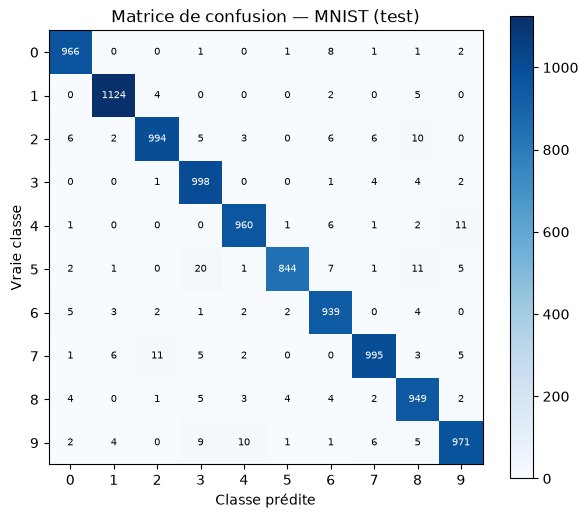

In [6]:
matrice = MulticlassConfusionMatrix(num_classes=10)(predictions, etiquettes)

plt.figure(figsize=(7, 6))
plt.imshow(matrice, cmap="Blues")
plt.colorbar()
for i in range(10):
    for j in range(10):
        plt.text(j, i, int(matrice[i, j]), ha="center", va="center", fontsize=7,
                 color="white" if matrice[i, j] > matrice.max() / 2 else "black")
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Classe prédite")
plt.ylabel("Vraie classe")
plt.title("Matrice de confusion — MNIST (test)")
plt.show()

In [7]:
# Confusions les plus fréquentes (hors diagonale)
hors_diag = matrice.clone()
hors_diag.fill_diagonal_(0)
valeurs, positions = hors_diag.flatten().topk(5)
for v, p in zip(valeurs, positions):
    print(f"vrai {p.item() // 10} -> prédit {p.item() % 10} : {v.item()} fois")

vrai 5 -> prédit 3 : 20 fois
vrai 7 -> prédit 2 : 11 fois
vrai 4 -> prédit 9 : 11 fois
vrai 5 -> prédit 8 : 11 fois
vrai 9 -> prédit 4 : 10 fois


## 5. Quelques images mal classées

Nombre d'images mal classées : 260 sur 10000


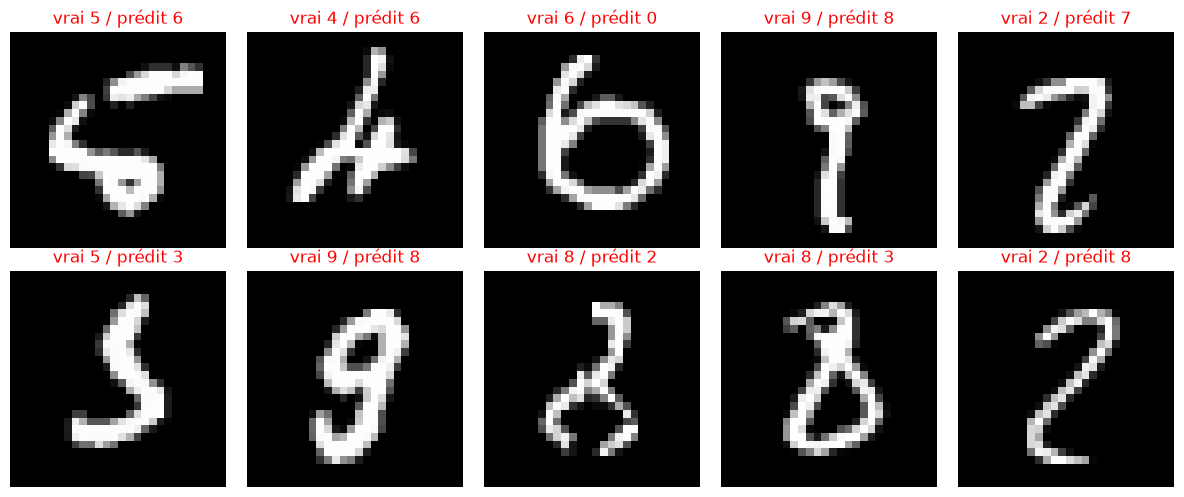

In [8]:
mal_classees = (predictions != etiquettes).nonzero(as_tuple=True)[0]
print("Nombre d'images mal classées :", len(mal_classees), "sur", len(etiquettes))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, mal_classees[:10]):
    ax.imshow(images_test[idx, 0], cmap="gray")
    ax.set_title(f"vrai {etiquettes[idx].item()} / prédit {predictions[idx].item()}", color="red")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Sauvegarder et recharger le modèle

On réutilise le réseau entraîné **sans recommencer l'apprentissage** : on sauvegarde le `state_dict`
(les paramètres), puis on le charge dans un modèle de même architecture.

In [9]:
chemin = "mnist_mlp.pth"
torch.save(model.state_dict(), chemin)
print("Modèle sauvegardé dans", chemin)

modele_recharge = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
modele_recharge.load_state_dict(torch.load(chemin, weights_only=True))
modele_recharge.eval()

predictions_rechargees, _, _ = predire(modele_recharge, test_loader)
print("Prédictions identiques :", torch.equal(predictions, predictions_rechargees))
print(f"Accuracy du modèle rechargé : {(predictions_rechargees == etiquettes).float().mean():.4f}")

Modèle sauvegardé dans mnist_mlp.pth


Prédictions identiques : True
Accuracy du modèle rechargé : 0.9740


## Conclusion

- Les **mini-lots** (64 images) permettent de nombreuses mises à jour par époque (938) sans charger tout le jeu en mémoire.
- `model.train()` / `model.eval()` changent le comportement de certaines couches (Dropout, BatchNorm) ; `torch.no_grad()` désactive le calcul des gradients pendant l'évaluation (plus rapide, moins de mémoire).
- Un simple réseau à une couche cachée atteint environ 97 % d'accuracy ; les erreurs portent surtout sur des chiffres proches visuellement (4/9, 3/5, 7/2).
- Le `state_dict` sauvegarde uniquement les poids : il faut recréer la même architecture avant de les recharger.